<a href="https://colab.research.google.com/github/ompatel420/FreeCodeCamp-Machine-Learning-Project/blob/main/Health_Costs_Calculator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [6]:
# Download insurance dataset from GitHub

!wget -O insurance.csv "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

# Load dataset
dataset = pd.read_csv("insurance.csv")

# Display dataset
display(dataset.head())

print("Dataset shape:", dataset.shape)
print("Dataset downloaded successfully!")

dataset = dataset.rename(columns={"charges": "expenses"})

--2026-11-07 07:02:54--  https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 54288 (53K) [text/plain]
Saving to: ‘insurance.csv’

insurance.csv       100%[===================>]  53.02K  --.-KB/s    in 0.01s   

2026-11-07 07:02:54 (4.63 MB/s) - ‘insurance.csv’ saved [54288/54288]



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Dataset shape: (1338, 7)
Dataset downloaded successfully!


In [7]:
# Convert categorical columns into numerical columns
dataset = pd.get_dummies(
    dataset,
    columns=['sex', 'smoker', 'region'],
    dtype=int
)

# Split dataset into training and testing data
train_dataset = dataset.sample(
    frac=0.8,
    random_state=0
)

test_dataset = dataset.drop(
    train_dataset.index
)

# Separate labels from features
train_labels = train_dataset.pop('expenses')
test_labels = test_dataset.pop('expenses')

# Display dataset information
print("Training dataset:", train_dataset.shape)
print("Testing dataset:", test_dataset.shape)

print("\nTraining labels:", train_labels.shape)
print("Testing labels:", test_labels.shape)

print("\nProcessed training data:")
display(train_dataset.head())

Training dataset: (1070, 11)
Testing dataset: (268, 11)

Training labels: (1070,)
Testing labels: (268,)

Processed training data:


,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
578,52,30.200,1,0,1,1,0,0,0,0,1
610,47,29.370,1,1,0,1,0,0,0,1,0
569,48,40.565,2,0,1,0,1,0,1,0,0
1034,61,38.380,0,0,1,1,0,0,1,0,0
198,51,18.050,0,1,0,1,0,0,1,0,0


In [8]:
# Create normalization layer
normalizer = layers.Normalization(axis=-1)

# Adapt normalizer using training data only
normalizer.adapt(
    np.asarray(train_dataset).astype('float32')
)

print("Normalization completed!")

Normalization completed!


In [9]:
# Create model
model = keras.Sequential([
    normalizer,

    layers.Dense(
        128,
        activation='relu'
    ),

    layers.Dropout(0.1),

    layers.Dense(
        64,
        activation='relu'
    ),

    layers.Dense(
        32,
        activation='relu'
    ),

    # Output layer for predicting healthcare expenses
    layers.Dense(1)
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.01
    ),

    loss='mean_absolute_error',

    metrics=['mean_absolute_error', 'mean_squared_error']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (1070, 11)             │            23 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23 (96.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23 (96.00 B)

In [10]:
# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

# Train model
history = model.fit(
    train_dataset,
    train_labels,

    epochs=300,

    validation_split=0.2,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/300
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 12397.5820 - mean_absolute_error: 12397.5820 - mean_squared_error: 294744000.0000 - val_loss: 12687.4326 - val_mean_absolute_error: 12687.4326 - val_mean_squared_error: 316415360.0000
Epoch 2/300
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7935.9912 - mean_absolute_error: 7935.9912 - mean_squared_error: 159206112.0000 - val_loss: 5082.0356 - val_mean_absolute_error: 5082.0356 - val_mean_squared_error: 78930032.0000
Epoch 3/300
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3478.9868 - mean_absolute_error: 3478.9868 - mean_squared_error: 40027928.0000 - val_loss: 3391.3596 - val_mean_absolute_error: 3391.3596 - val_mean_squared_error: 47064112.0000
Epoch 4/300
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3037.3511 - mean_absolute_error: 3037.3511 - mean_squared_error: 36075280.0000 - val_loss: 3129.6304 - val_mean_absolute_error: 3129.6304 - val_mean_squared_error: 36914664.0000
Epoch 5/300
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5m

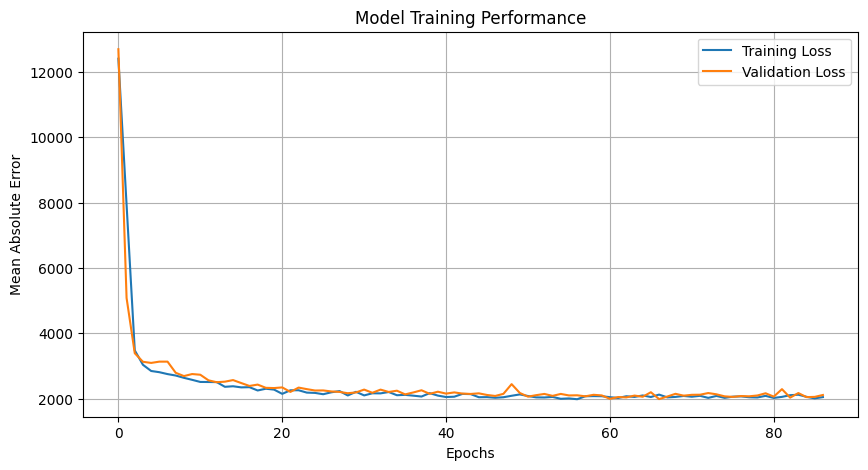

In [11]:
# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error')
plt.title('Model Training Performance')

plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Evaluate model
loss, mae, mse = model.evaluate(
    test_dataset,
    test_labels,
    verbose=2
)

print("\nModel Evaluation Results")
print("------------------------")

print(f"Mean Absolute Error: ${mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")

if mae < 3500:
    print("\nCongratulations! Your model passed the accuracy requirement!")
else:
    print("\nModel needs improvement.")

9/9 - 0s - 15ms/step - loss: 2581.9258 - mean_absolute_error: 2581.9258 - mean_squared_error: 35823232.0000

Model Evaluation Results
------------------------
Mean Absolute Error: $2581.93
Mean Squared Error: 35823232.00

Congratulations! Your model passed the accuracy requirement!


In [13]:
# Predict healthcare expenses
test_predictions = model.predict(
    test_dataset
).flatten()

# Display predictions
results = pd.DataFrame({
    'Actual Expenses': test_labels.values,
    'Predicted Expenses': test_predictions
})

print(results.head(15))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
    Actual Expenses  Predicted Expenses
0       27808.72510        27810.445312
1       37701.87680        31356.902344
2        6203.90175         6229.048828
3       14001.13380        14381.975586
4        2775.19215         2909.451172
5        4687.79700         4854.192383
6       13770.09790        13675.891602
7       15612.19335        15500.616211
8        4949.75870         4937.778320
9        6313.75900         6319.021484
10      34303.16720        24306.125000
11       6389.37785         6332.121094
12      17663.14420        17156.158203
13      11741.72600        11854.011719
14      11946.62590        11927.787109


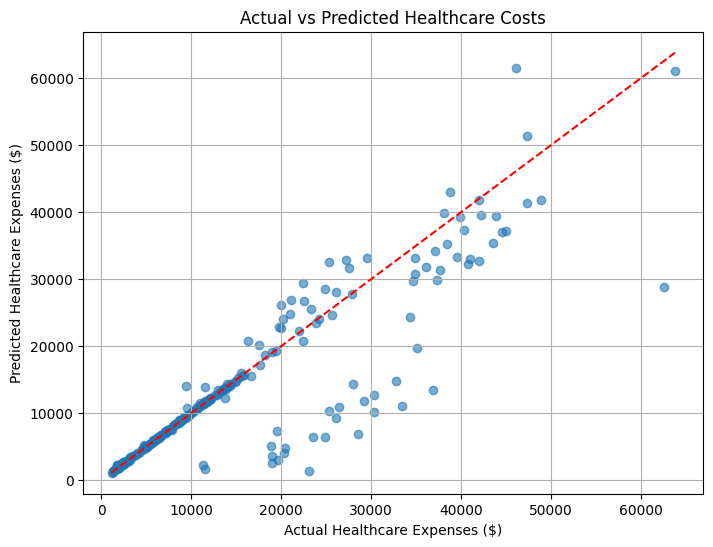

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    test_labels,
    test_predictions,
    alpha=0.6
)

plt.xlabel('Actual Healthcare Expenses ($)')
plt.ylabel('Predicted Healthcare Expenses ($)')

plt.title('Actual vs Predicted Healthcare Costs')

# Ideal prediction line
minimum = min(test_labels.min(), test_predictions.min())
maximum = max(test_labels.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.grid(True)
plt.show()

9/9 - 0s - 7ms/step - loss: 2581.9258 - mean_absolute_error: 2581.9258 - mean_squared_error: 35823232.0000

Mean Absolute Error: 2581.92578125
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


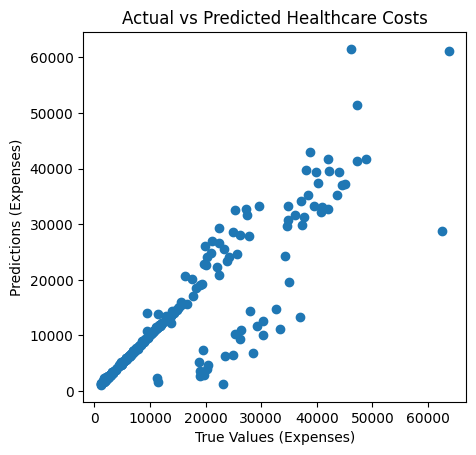

Congratulations! You passed the challenge!


In [15]:
# Evaluate the model
loss, mae, mse = model.evaluate(
    test_dataset,
    test_labels,
    verbose=2
)

print("\nMean Absolute Error:", mae)

# Predict healthcare expenses
test_predictions = model.predict(test_dataset).flatten()

# Compare actual and predicted expenses
a = plt.axes(aspect='equal')

plt.scatter(test_labels, test_predictions)

plt.xlabel('True Values (Expenses)')
plt.ylabel('Predictions (Expenses)')

plt.title('Actual vs Predicted Healthcare Costs')

plt.show()

# Check challenge requirement
if mae < 3500:
    print("Congratulations! You passed the challenge!")
else:
    print("You need to improve your model.")